# Week 4 (Part A): Optimizing the TF-IDF Model + SHAP Explanations
**Project:** Claude or Classifier? Cost-Aware Triage of App User Feedback, Westin Pals, MSAI-699-B01

All choices in this notebook are made with **5-fold cross-validation on the training set only**. The held-out test set (1,170 reviews, fixed in `src/data_prep.py`) is touched once at the end, so the test score is an honest estimate.

Experiments:
1. Feature engineering: word n-gram ranges, character n-grams, word + character combined, and a star-rating ablation (shortcut test).
2. Hyperparameter tuning: regularization strength `C` and class weighting.
3. Per-label decision thresholds tuned on out-of-fold predictions.
4. SHAP explanations (global and local) for the tuned model.
5. Fairness and risk slices: by app, review length, and emoji/non-English text.

In [1]:
import json, os, sys, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_recall_fscore_support, accuracy_score, hamming_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import FeatureUnion, Pipeline
warnings.filterwarnings('ignore')

ROOT = os.path.abspath('..'); sys.path.insert(0, os.path.join(ROOT, 'src'))
from data_prep import LABELS, APPS, RANDOM_STATE, load_prepared
RESULTS = os.path.join(ROOT, 'results'); os.makedirs(os.path.join(RESULTS, 'figures'), exist_ok=True)

df, _ = load_prepared(save=False)
train, test = df[df.split == 'train'].reset_index(drop=True), df[df.split == 'test'].reset_index(drop=True)
Y_train, Y_test = train[LABELS].values, test[LABELS].values
skf = list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(train, train['label_combo']))
print(len(train), len(test))

4676 1170


## 1. Model factory and cross-validation helpers
One logistic regression per label (one-vs-rest). `oof_proba` returns out-of-fold probabilities so thresholds can be tuned without touching the test set.

In [2]:
class TextCol(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X): return X['text'].values

class RatingOneHot(BaseEstimator, TransformerMixin):
    """Star rating as 5 one-hot columns, used only in the shortcut ablation."""
    def fit(self, X, y=None): return self
    def transform(self, X):
        s = X['score'].values.astype(int)
        return csr_matrix(np.eye(5)[s - 1])

def text_features(kind):
    word12 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents='unicode')
    word13 = TfidfVectorizer(ngram_range=(1, 3), min_df=2, sublinear_tf=True, strip_accents='unicode')
    char = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=60000)
    return {'word_1-2': word12, 'word_1-3': word13, 'char_2-5': char,
            'word_1-2+char_2-5': FeatureUnion([('w', word12), ('c', char)])}[kind]

def build_features(kind, rating=False):
    parts = [('text', Pipeline([('col', TextCol()), ('vec', text_features(kind))]))]
    if rating: parts.append(('rating', RatingOneHot()))
    return FeatureUnion(parts)

def fit_predict_proba(kind, X_tr, Y_tr, X_te, C=1.0, balanced=True, rating=False):
    feats = build_features(kind, rating).fit(X_tr)
    A_tr, A_te = feats.transform(X_tr), feats.transform(X_te)
    P = np.zeros((len(X_te), len(LABELS)))
    models = []
    for j in range(len(LABELS)):
        m = LogisticRegression(C=C, class_weight='balanced' if balanced else None,
                               solver='liblinear', max_iter=3000, random_state=RANDOM_STATE)
        m.fit(A_tr, Y_tr[:, j]); P[:, j] = m.predict_proba(A_te)[:, 1]; models.append(m)
    return P, feats, models

def oof_proba(kind, **kw):
    P = np.zeros(Y_train.shape)
    for tr, va in skf:
        P[va], _, _ = fit_predict_proba(kind, train.iloc[tr], Y_train[tr], train.iloc[va], **kw)
    return P

def scores(Y, P, thr=0.5):
    pred = (P >= np.asarray(thr)).astype(int)
    p, r, f, _ = precision_recall_fscore_support(Y, pred, zero_division=0)
    out = {'macro_f1': f1_score(Y, pred, average='macro', zero_division=0),
           'micro_f1': f1_score(Y, pred, average='micro', zero_division=0),
           'subset_acc': accuracy_score(Y, pred), 'hamming': hamming_loss(Y, pred)}
    for i, l in enumerate(LABELS): out.update({f'{l}_p': p[i], f'{l}_r': r[i], f'{l}_f1': f[i]})
    return out, pred

## 2. Feature engineering (CV on training set, C = 1, balanced weights)

In [3]:
fe_rows, OOF = [], {}
for kind in ['word_1-2', 'word_1-3', 'char_2-5', 'word_1-2+char_2-5']:
    t0 = time.perf_counter(); OOF[kind] = oof_proba(kind)
    s, _ = scores(Y_train, OOF[kind])
    fe_rows.append({'features': kind, **{k: s[k] for k in ['macro_f1', 'problem_report_f1', 'feature_request_f1', 'irrelevant_f1']},
                    'cv_seconds': time.perf_counter() - t0})
fe = pd.DataFrame(fe_rows).round(3); fe

,features,macro_f1,problem_report_f1,feature_request_f1,irrelevant_f1,cv_seconds
0,word_1-2,0.829,0.854,0.714,0.921,1.507
1,word_1-3,0.827,0.850,0.710,0.921,2.469
2,char_2-5,0.834,0.862,0.718,0.924,8.977
3,word_1-2+char_2-5,0.849,0.872,0.741,0.934,9.624


### Star-rating ablation (shortcut test)
Week 2 found that star rating tracks the labels closely. Adding it shows how much a model *could* lean on the rating instead of the text. The production model stays text-only, because a review with no rating (support tickets, chat) would break a rating-dependent model, and a model that reads the rating is not really reading the feedback.

In [4]:
best_kind = fe.sort_values('macro_f1', ascending=False).iloc[0]['features']
OOF['rating'] = oof_proba(best_kind, rating=True)
s_txt, _ = scores(Y_train, OOF[best_kind]); s_rat, _ = scores(Y_train, OOF['rating'])
ablation = pd.DataFrame([{'model': f'{best_kind} (text only)', **{k: s_txt[k] for k in ['macro_f1','problem_report_f1','feature_request_f1','irrelevant_f1']}},
                         {'model': f'{best_kind} + star rating', **{k: s_rat[k] for k in ['macro_f1','problem_report_f1','feature_request_f1','irrelevant_f1']}}]).round(3)
print('best text-only features:', best_kind); ablation

best text-only features: word_1-2+char_2-5


,model,macro_f1,problem_report_f1,feature_request_f1,irrelevant_f1
0,word_1-2+char_2-5 (text only),0.849,0.872,0.741,0.934
1,word_1-2+char_2-5 + star rating,0.845,0.861,0.745,0.929


## 3. Hyperparameter tuning: C and class weighting

In [5]:
hp_rows = []
for C_ in [0.25, 0.5, 1, 2, 4, 8, 16]:
    for bal in [True, False]:
        P = oof_proba(best_kind, C=C_, balanced=bal); s, _ = scores(Y_train, P)
        hp_rows.append({'C': C_, 'balanced': bal, 'macro_f1': s['macro_f1'], 'feature_request_f1': s['feature_request_f1']})
        OOF[(C_, bal)] = P
hp = pd.DataFrame(hp_rows).round(3)
best = hp.sort_values('macro_f1', ascending=False).iloc[0]
best_C, best_bal = float(best['C']), bool(best['balanced'])
print('best C', best_C, 'balanced', best_bal)
hp.pivot(index='C', columns='balanced', values='macro_f1')

best C 4.0 balanced True


balanced,False,True
C,,
0.25,0.747,0.830
0.50,0.800,0.839
1.00,0.829,0.849
2.00,0.841,0.854
4.00,0.843,0.856
8.00,0.848,0.854
16.00,0.847,0.854


## 4. Per-label decision thresholds (tuned on out-of-fold predictions)

In [6]:
P_oof = OOF[(best_C, best_bal)]
grid = np.round(np.arange(0.2, 0.81, 0.025), 3)
thr = []
for j, l in enumerate(LABELS):
    f = [f1_score(Y_train[:, j], (P_oof[:, j] >= t).astype(int)) for t in grid]
    thr.append(float(grid[int(np.argmax(f))]))
s05, _ = scores(Y_train, P_oof, 0.5); stun, _ = scores(Y_train, P_oof, thr)
print('thresholds', dict(zip(LABELS, thr)))
print(f"CV macro F1: threshold 0.5 = {s05['macro_f1']:.3f} | tuned thresholds = {stun['macro_f1']:.3f}")

thresholds {'problem_report': 0.475, 'feature_request': 0.525, 'irrelevant': 0.475}
CV macro F1: threshold 0.5 = 0.856 | tuned thresholds = 0.857


## 5. Final test: baseline vs. tuned model (test set used once)

In [7]:
t0 = time.perf_counter()
P_base, _, _ = fit_predict_proba('word_1-2', train, Y_train, test)
P_tuned, feats, models = fit_predict_proba(best_kind, train, Y_train, test, C=best_C, balanced=best_bal)
fit_sec = time.perf_counter() - t0
t0 = time.perf_counter(); _ = np.column_stack([m.predict_proba(feats.transform(test))[:, 1] for m in models]); inf_sec = time.perf_counter() - t0
s_base, pred_base = scores(Y_test, P_base, 0.5)
s_tuned, pred_tuned = scores(Y_test, P_tuned, thr)
cmp = pd.DataFrame([{'model': 'Week 3 baseline (word 1-2, C=1, thr 0.5)', **s_base},
                    {'model': f'Tuned TF-IDF ({best_kind}, C={best_C}, tuned thr)', **s_tuned}]).set_index('model').T.round(3)
print(f'inference {1000*inf_sec/len(test):.3f}s per 1,000 reviews, $0 API cost')
cmp

inference 0.645s per 1,000 reviews, $0 API cost


model,"Week 3 baseline (word 1-2, C=1, thr 0.5)","Tuned TF-IDF (word_1-2+char_2-5, C=4.0, tuned thr)"
macro_f1,0.821,0.846
micro_f1,0.847,0.877
subset_acc,0.761,0.815
hamming,0.109,0.085
problem_report_p,0.790,0.849
problem_report_r,0.896,0.911
problem_report_f1,0.840,0.879
feature_request_p,0.611,0.684
feature_request_r,0.830,0.755
feature_request_f1,0.704,0.718


## 6. SHAP: what drives the tuned model's predictions
SHAP `LinearExplainer` gives each n-gram's contribution (in log-odds) to each prediction. Global importance = mean absolute SHAP value over the test set.

Background dataset has 4676 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4676 when initializing the masker.


Background dataset has 4676 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4676 when initializing the masker.


Background dataset has 4676 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4676 when initializing the masker.


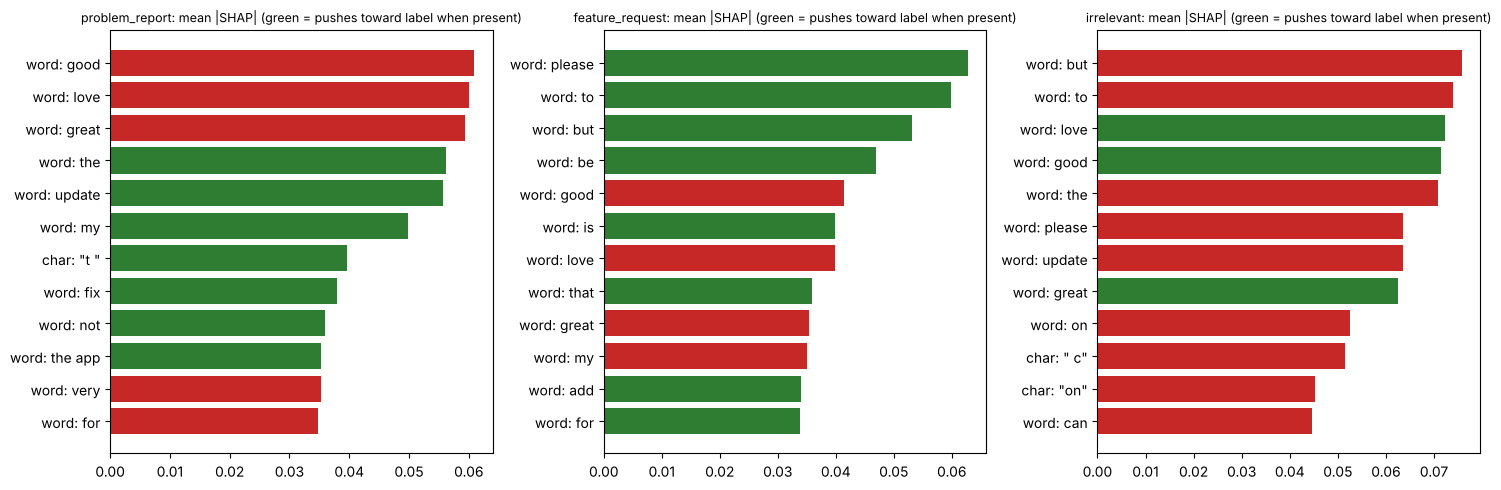

In [8]:
import shap
A_tr, A_te = feats.transform(train), feats.transform(test)
names = np.concatenate([t[1].named_steps['vec'].get_feature_names_out() if hasattr(t[1].named_steps['vec'], 'get_feature_names_out')
                        else np.concatenate([v.get_feature_names_out() for _, v in t[1].named_steps['vec'].transformer_list])
                        for t in feats.transformer_list])
pretty = np.array([('word: ' + n[3:]) if n.startswith('w__') else ('char: "' + n[3:] + '"') for n in names])
fr = LABELS.index('feature_request')
shap_vals = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for j, l in enumerate(LABELS):
    ex = shap.LinearExplainer(models[j], A_tr, feature_perturbation='interventional')
    sv = ex.shap_values(A_te); sv = sv.toarray() if hasattr(sv, 'toarray') else np.asarray(sv)
    shap_vals[l] = sv
    imp = np.abs(sv).mean(0); top = np.argsort(imp)[-12:]
    present = (A_te[:, top] > 0).toarray()
    direction = [sv[present[:, k], t].mean() if present[:, k].any() else 0 for k, t in enumerate(top)]
    axes[j].barh([pretty[i] for i in top], imp[top], color=['#2E7D32' if d > 0 else '#C62828' for d in direction])
    axes[j].set_title(f'{l}: mean |SHAP| (green = pushes toward label when present)', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'figures', 'shap_global_tfidf.png'), dpi=150); plt.show()

### Local explanations: why individual reviews were labeled the way they were

In [9]:
def explain(i, label, k=6):
    j = LABELS.index(label); sv = shap_vals[label][i]
    idx = np.argsort(np.abs(sv))[-k:][::-1]
    return ', '.join(f"{pretty[t]} {sv[t]:+.2f}" for t in idx)

pred_fr = (P_tuned[:, fr] >= thr[fr]).astype(int)
cases = {'correct feature request': np.where((Y_test[:, fr] == 1) & (pred_fr == 1))[0][0],
         'false-positive feature request': np.where((Y_test[:, fr] == 0) & (pred_fr == 1))[0][0],
         'missed feature request': np.where((Y_test[:, fr] == 1) & (pred_fr == 0))[0][0]}
for name, i in cases.items():
    print(f'[{name}] p={P_tuned[i, fr]:.2f} | "{test.text[i][:150]}"\n   top SHAP: {explain(i, "feature_request")}\n')

[correct feature request] p=0.55 | "1. The earlier version was about to alert me on Carousell. Now it cannot. 2. I m from Singapore. Yet, the details show I m in Malaysia. These are comp"
   top SHAP: word: in +0.16, word: was +0.15, word: yet +0.14, word: version was +0.12, word: now it -0.12, word: me -0.11

[false-positive feature request] p=0.70 | "Generally good but Body Battery and Stress tabs don't work during some activities, for example Hiking, which renders the features practically useless "
   top SHAP: word: good but +0.38, word: don +0.18, word: but +0.16, word: battery and +0.16, word: anyone +0.14, word: don work -0.14

[missed feature request] p=0.45 | "Not very accurate will not sink - MyFitnessPal would not buy again. Mobile app error all the time."
   top SHAP: word: would +0.46, word: accurate -0.24, word: not very +0.22, word: will +0.17, word: myfitnesspal +0.16, word: all -0.15



## 7. Fairness and risk slices (tuned model, test set)
The costliest error for a product team is a **missed problem report** (a real user issue silently ignored), so the problem-report miss rate (false negative rate) is reported per slice.

In [10]:
def is_emoji_or_nonascii(s): return sum(ord(c) > 127 for c in s) / max(len(s), 1) > 0.2
words = test.text.str.split().str.len()
slices = {**{f'app: {a}': (test.app == a).values for a in APPS},
          'length: <= 3 words': (words <= 3).values, 'length: 4-20 words': ((words > 3) & (words <= 20)).values,
          'length: > 20 words': (words > 20).values,
          'emoji / non-English heavy': test.text.map(is_emoji_or_nonascii).values}
pr = LABELS.index('problem_report')
rows = []
for name, m in slices.items():
    yt, yp = Y_test[m], pred_tuned[m]
    pos = yt[:, pr] == 1
    rows.append({'slice': name, 'n': int(m.sum()), 'macro_f1': f1_score(yt, yp, average='macro', zero_division=0),
                 'problem_report_miss_rate': float(((yp[:, pr] == 0) & pos).sum() / max(pos.sum(), 1)), 'n_problem_reports': int(pos.sum())})
fair = pd.DataFrame(rows).round(3); fair

,slice,n,macro_f1,problem_report_miss_rate,n_problem_reports
0,app: Garmin Connect,401,0.818,0.119,118
1,app: Huawei Health,389,0.832,0.062,176
2,app: Samsung Health,380,0.863,0.099,101
3,length: <= 3 words,206,0.668,0.286,7
4,length: 4-20 words,540,0.831,0.108,148
5,length: > 20 words,424,0.813,0.071,240
6,emoji / non-English heavy,11,0.333,0.000,0


In [11]:
summary = {'feature_engineering_cv': fe.to_dict('records'), 'rating_ablation_cv': ablation.to_dict('records'),
           'hyperparameter_cv': hp.to_dict('records'), 'best': {'features': best_kind, 'C': best_C, 'balanced': best_bal,
           'thresholds': dict(zip(LABELS, thr))}, 'cv_macro_f1_thr05': s05['macro_f1'], 'cv_macro_f1_tuned_thr': stun['macro_f1'],
           'test_baseline': s_base, 'test_tuned': s_tuned, 'fairness_slices': fair.to_dict('records'),
           'inference_seconds_per_1000': 1000 * inf_sec / len(test)}
json.dump(summary, open(os.path.join(RESULTS, 'tfidf_tuned_metrics.json'), 'w'), indent=2, default=float)
out = test[['review_id', 'app', 'text'] + LABELS].copy()
for j, l in enumerate(LABELS): out[f'proba_{l}'] = P_tuned[:, j]; out[f'pred_{l}'] = pred_tuned[:, j]
out.to_csv(os.path.join(RESULTS, 'tfidf_tuned_test_predictions.csv'), index=False); print('saved')

saved
